# 0.1. Исходный датасет

## Загружаем и смотрим на исходный датасет

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import os, shutil, json
from google.colab import files

path = kagglehub.dataset_download("antonkozyriev/game-recommendations-on-steam")
print("Path to dataset files:", path)
!ls /root/.cache/kagglehub/datasets/antonkozyriev/game-recommendations-on-steam/versions/28

100%|██████████| 660M/660M [00:06<00:00, 100MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/antonkozyriev/game-recommendations-on-steam/versions/28
games.csv  games_metadata.json	recommendations.csv  users.csv


In [ ]:
recommendations_df = pd.read_csv(f"{path}/recommendations.csv")
recommendations_df["date"] = pd.to_datetime(recommendations_df["date"])
users_df = pd.read_csv(f"{path}/users.csv")
games_df = pd.read_csv(f"{path}/games.csv")

In [ ]:
#games_metadata = pd.read_json(f"{path}/games_metadata.json")
#!cat /root/.cache/kagglehub/datasets/antonkozyriev/game-recommendations-on-steam/versions/28/games_metadata.json

In [ ]:
n_users = recommendations_df["user_id"].nunique()
n_items = recommendations_df["app_id"].nunique()
n_inter = len(recommendations_df)
n_pairs = recommendations_df[["user_id", "app_id"]].drop_duplicates().shape[0]

print(f"users={n_users}, items={n_items}, interactions={n_inter}, unique pairs={n_pairs}")
print(f"density={n_inter / (n_users * n_items):.8f}")
print(f"duplicates (user,item) = {n_inter - n_pairs}")

users=13781059, items=37610, interactions=41154794, unique pairs=41154773
density=0.00007940
duplicates (user,item) = 21


In [ ]:
users_df

,user_id,products,reviews
0,7360263,359,0
1,14020781,156,1
2,8762579,329,4
3,4820647,176,4
4,5167327,98,2
...,...,...,...
14306059,5047430,6,0
14306060,5048153,0,0
14306061,5059205,31,0
14306062,5074363,0,0


In [ ]:
games_df

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
50867,2296380,I Expect You To Die 3: Cog in the Machine,2023-09-28,True,False,False,Very Positive,96,101,22.00,0.00,0.0,True
50868,1272080,PAYDAY 3,2023-09-21,True,False,False,Mostly Negative,38,29458,40.00,0.00,0.0,True
50869,1402110,Eternights,2023-09-11,True,False,False,Very Positive,89,1128,30.00,0.00,0.0,True
50870,2272250,Forgive Me Father 2,2023-10-19,True,False,False,Very Positive,95,82,17.00,0.00,0.0,True


In [ ]:
recommendations_df

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.3,51580,0
1,304390,4,0,2017-02-17,False,11.5,2586,1
2,1085660,2,0,2019-11-17,True,336.5,253880,2
3,703080,0,0,2022-09-23,True,27.4,259432,3
4,526870,0,0,2021-01-10,True,7.9,23869,4
...,...,...,...,...,...,...,...,...
41154789,633230,0,0,2021-02-15,True,41.0,1606890,41154789
41154790,758870,8,0,2019-07-18,False,8.0,1786254,41154790
41154791,696170,3,10,2018-03-26,False,2.0,6370324,41154791
41154792,696170,0,0,2018-06-11,True,4.0,1044289,41154792


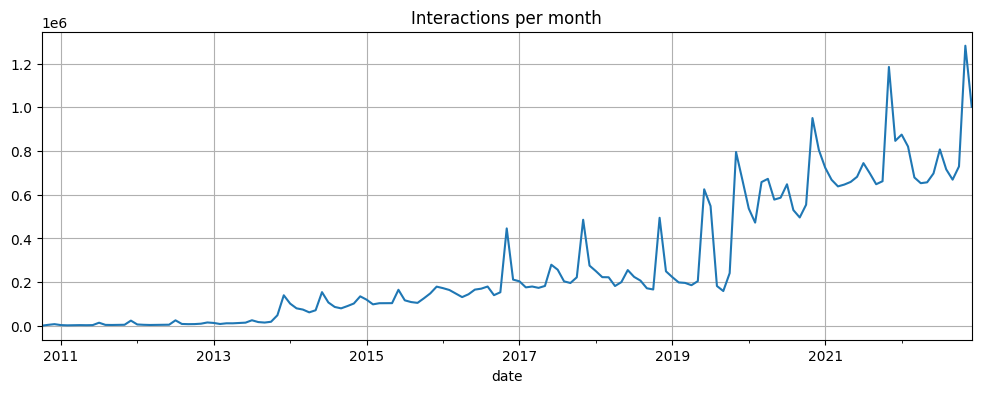

In [ ]:
try: del monthly
except: pass
monthly = recommendations_df['date'].dt.to_period("M").value_counts().sort_index()
monthly.plot(figsize=(12, 4), title="Interactions per month", grid=True)
plt.show()

Распределение пользователей по reviews


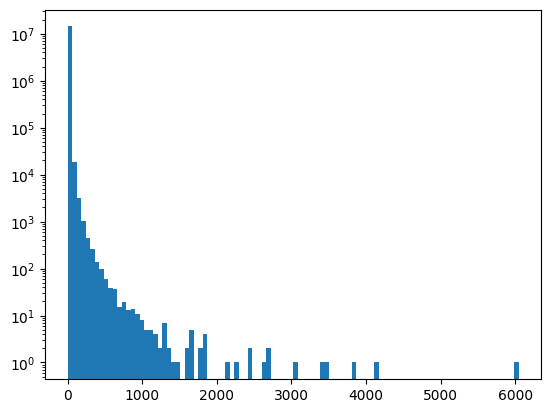

In [ ]:
plt.hist(users_df["reviews"], bins=100, log=True)
print('Распределение пользователей по reviews')

Распределение игр по reviews


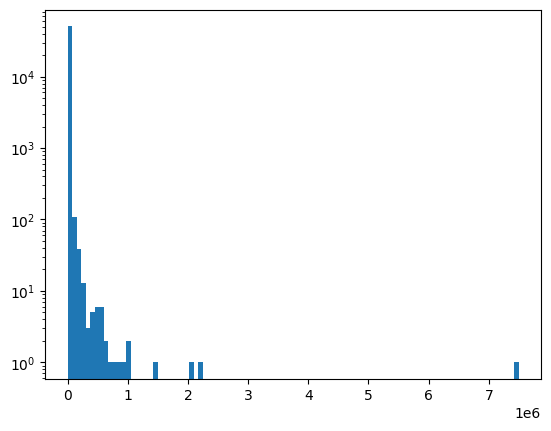

In [ ]:
plt.hist(games_df["user_reviews"], bins=100, log=True)
print('Распределение игр по reviews')

## Сужаем выборку

* Берём 2022 год
* **Пользователей хотя бы с 10 отзывами**
* **Игры хотя бы с 50 отзывами**
* Оставляем 25% пользователей (seed=0)
* Оставляем 99% игр (seed=1)

In [ ]:
recommendations_df_2022 = recommendations_df[recommendations_df["date"] >= datetime.strptime('2022-01-01', "%Y-%m-%d")][recommendations_df["date"] < datetime.strptime('2023-01-01', "%Y-%m-%d")]

/tmp/ipykernel_663/3535191465.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  recommendations_df_2022 = recommendations_df[recommendations_df["date"] >= datetime.strptime('2022-01-01', "%Y-%m-%d")][recommendations_df["date"] < datetime.strptime('2023-01-01', "%Y-%m-%d")]


In [ ]:
print('Длина recommendations датасета за 2022 год:', len(recommendations_df_2022))

Длина recommendations датасета за 2022 год: 9589527


In [ ]:
temp_u1 = recommendations_df_2022.groupby('user_id')['is_recommended'].count().sort_values()
temp_g1 = recommendations_df_2022.groupby('app_id')['is_recommended'].count().sort_values()
temp_u1 = temp_u1.rename("reviews")
temp_g1 = temp_g1.rename("reviews")

In [ ]:
#plt.hist(users_df["reviews"][users_df["reviews"] >= 5], bins=100, log=True)
for cutoff in [0, 5, 10, 20, 50, 100]:
  print(f'Пользователей хотя бы с {cutoff:<3} отзывами', (temp_u1 >= cutoff).sum())
for cutoff in [0, 5, 10, 20, 50, 100]:
  print(f'Игр хотя бы с {cutoff:<3} отзывами', (temp_g1 >= cutoff).sum())

Пользователей хотя бы с 0   отзывами 5268834
Пользователей хотя бы с 5   отзывами 291807
Пользователей хотя бы с 10  отзывами 75302
Пользователей хотя бы с 20  отзывами 17247
Пользователей хотя бы с 50  отзывами 2157
Пользователей хотя бы с 100 отзывами 439
Игр хотя бы с 0   отзывами 32747
Игр хотя бы с 5   отзывами 21430
Игр хотя бы с 10  отзывами 16035
Игр хотя бы с 20  отзывами 11325
Игр хотя бы с 50  отзывами 7132
Игр хотя бы с 100 отзывами 5008


In [ ]:
temp_u2 = temp_u1[temp_u1 >= 10].sample(frac=0.25, random_state=0)
temp_g2 = temp_g1[temp_g1 >= 50].sample(frac=0.99, random_state=1)

sub = recommendations_df_2022.loc[
    recommendations_df_2022["user_id"].isin(temp_u2.index) &
    recommendations_df_2022["app_id"].isin(temp_g2.index)
]
n_users = sub["user_id"].nunique()
n_items = sub["app_id"].nunique()
n_inter = len(sub)
n_pairs = sub[["user_id", "app_id"]].drop_duplicates().shape[0]

print(f"users={n_users}, items={n_items}, interactions={n_inter}, unique pairs={n_pairs}")
print(f"density={n_inter / (n_users * n_items):.8f}")
print(f"duplicates (user,item) = {n_inter - n_pairs}")

users=18825, items=7017, interactions=309282, unique pairs=309282
density=0.00234136
duplicates (user,item) = 0


In [ ]:
sub.reset_index(drop=True)

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,534380,0,0,2022-10-08,True,40.6,22793,22
1,394360,0,0,2022-08-13,True,179.7,12241689,227
2,1174180,0,0,2022-05-18,True,411.6,8449375,584
3,312520,0,0,2022-10-04,True,114.3,1593850,606
4,289070,0,0,2022-08-14,True,24.1,3909085,626
...,...,...,...,...,...,...,...,...
309277,915810,0,0,2022-05-20,False,0.0,9650854,41153998
309278,287390,0,0,2022-10-25,True,4.0,3670192,41154413
309279,1366540,0,0,2022-09-05,True,139.0,3486408,41154436
309280,1969870,4,0,2022-06-29,True,2.0,1061506,41154541


In [ ]:
new_users_df = users_df[users_df["user_id"].isin(temp_u2.index)].reset_index(drop=True)
new_users_df

,user_id,products,reviews
0,50405,502,97
1,10181930,866,78
2,11409949,82,12
3,11632810,1529,43
4,11923957,1611,21
...,...,...,...
18821,3073366,244,20
18822,3281411,32,11
18823,3297599,38,13
18824,3516715,189,28


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
new_games_df = games_df[games_df["app_id"].isin(temp_g2.index)].reset_index(drop=True)
new_games_df

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
2,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
3,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True
4,250180,METAL SLUG 3,2015-09-14,True,False,False,Very Positive,90,5579,7.99,7.99,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7056,632470,Disco Elysium - The Final Cut,2019-10-15,True,True,False,Very Positive,93,75060,40.00,0.00,0.0,True
7057,1599660,Sackboy™: A Big Adventure,2022-10-27,True,False,False,Very Positive,85,1154,60.00,0.00,0.0,True
7058,250900,The Binding of Isaac: Rebirth,2014-11-04,True,True,True,Overwhelmingly Positive,97,225815,15.00,0.00,0.0,True
7059,920210,LEGO® Star Wars™: The Skywalker Saga,2022-04-05,True,False,False,Very Positive,91,30937,50.00,0.00,0.0,True


In [ ]:
dst = "steam_subset"
os.makedirs(dst, exist_ok=True)
sub.to_csv(f"{dst}/recommendations.csv", index=False)
new_users_df.to_csv(f"{dst}/users.csv", index=False)
new_games_df.to_csv(f"{dst}/games.csv", index=False)
shutil.copyfile(f"{path}/games_metadata.json", f"{dst}/games_metadata.json")

shutil.make_archive("steam_subset", "zip", root_dir=".", base_dir="steam_subset")

'/content/steam_subset.zip'

In [ ]:
files.download("steam_subset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 0.2 Скачиваем изменённый датасет и EDA

## Imports & Install

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import os, shutil, json
from google.colab import files
import gdown
import sklearn
import itertools

dataset_file_id = "14SifNAX8Mt_h8ZzkPfLnj9k-OL8qzEbp"
gdown.download(id=dataset_file_id, output="steam_subset.zip", quiet=False)
shutil.unpack_archive("steam_subset.zip", extract_dir=".")
os.remove("steam_subset.zip")
path = 'steam_subset'

Downloading...
From: https://drive.google.com/uc?id=14SifNAX8Mt_h8ZzkPfLnj9k-OL8qzEbp
To: /content/steam_subset.zip
100%|██████████| 10.7M/10.7M [00:00<00:00, 50.7MB/s]


In [2]:
!pip install sentence-transformers


## Visuals & EDA



Название **Game Recommendations on Steam**

Ссылка на источник https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam/data

Как датасет сузил

* Берём 2022 год
* **Пользователей хотя бы с 10 отзывами**
* **Игры хотя бы с 50 отзывами**
* Оставляем 25% пользователей (seed=0)
* Оставляем 99% игр (seed=1)

Смысл полей и взаимодействий

- app_id - id игры
- user_id - id пользователя
- funny - сколько человек посчитали отзыв смешным
- helpful - сколько человек посчитали отзыв полезным
- date - дата отзыва
- is_recommended - оценка user-а на отзыв [True, False]
- hours - сколько часов user играл в игру
- products - Number of games/add-ons purchased by the user
- reviews - Number of reviews published (всего)
- title - Название игры
- date_release - Дата выхода игры
- win,	mac,	linux - доступна ли игра на windows, mac os, linux
- rating - Product rating category
- positive_ratio - Ratio of positive feedbacks
- user_reviews - Amount of user reviews availble on the Steam page (NOT in the dataset)
- price_final - Price in US dollars \$ calculated after the discount
- price_original - Price in US dollars \$ before the discount
- discount - Discount percentage
- steam_deck - Has support on the Steam Deck?
- (games_metadata.json) description - Описание игры
- (games_metadata.json) tags - Жанры игры

Исходный и итоговый объём

- Исходно 41 154 794 взаимодействий с 2011 по 2023 год
- Итоговый объём: 309 282 взаимодействий за полный 2022 год, users=18 825, items=7 017

Что рекомендуете и что считаете релевантным объектом

- Взаимодействие = отзыв пользователя на игру
- Рекоммендуем игры
- Релевантным на test считается положительный отзыв на игру в test-подвыборке




In [3]:
recommendations_df = pd.read_csv(f"{path}/recommendations.csv")
recommendations_df["date"] = pd.to_datetime(recommendations_df["date"])
users_df = pd.read_csv(f"{path}/users.csv")
games_df = pd.read_csv(f"{path}/games.csv")

n_users = recommendations_df["user_id"].nunique()
n_items = recommendations_df["app_id"].nunique()
n_inter = len(recommendations_df)
n_pairs = recommendations_df[["user_id", "app_id"]].drop_duplicates().shape[0]

print(f"users={n_users}, items={n_items}, interactions={n_inter}, unique pairs={n_pairs}")
print(f"density={n_inter / (n_users * n_items):.8f}")
print(f"duplicates (user,item) = {n_inter - n_pairs}")

users=18825, items=7017, interactions=309282, unique pairs=309282
density=0.00234136
duplicates (user,item) = 0


In [4]:
recommendations_df

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,534380,0,0,2022-10-08,True,40.6,22793,22
1,394360,0,0,2022-08-13,True,179.7,12241689,227
2,1174180,0,0,2022-05-18,True,411.6,8449375,584
3,312520,0,0,2022-10-04,True,114.3,1593850,606
4,289070,0,0,2022-08-14,True,24.1,3909085,626
...,...,...,...,...,...,...,...,...
309277,915810,0,0,2022-05-20,False,0.0,9650854,41153998
309278,287390,0,0,2022-10-25,True,4.0,3670192,41154413
309279,1366540,0,0,2022-09-05,True,139.0,3486408,41154436
309280,1969870,4,0,2022-06-29,True,2.0,1061506,41154541


In [5]:
users_df

,user_id,products,reviews
0,50405,502,97
1,10181930,866,78
2,11409949,82,12
3,11632810,1529,43
4,11923957,1611,21
...,...,...,...
18821,3073366,244,20
18822,3281411,32,11
18823,3297599,38,13
18824,3516715,189,28


In [6]:
games_df

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
2,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
3,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True
4,250180,METAL SLUG 3,2015-09-14,True,False,False,Very Positive,90,5579,7.99,7.99,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7056,632470,Disco Elysium - The Final Cut,2019-10-15,True,True,False,Very Positive,93,75060,40.00,0.00,0.0,True
7057,1599660,Sackboy™: A Big Adventure,2022-10-27,True,False,False,Very Positive,85,1154,60.00,0.00,0.0,True
7058,250900,The Binding of Isaac: Rebirth,2014-11-04,True,True,True,Overwhelmingly Positive,97,225815,15.00,0.00,0.0,True
7059,920210,LEGO® Star Wars™: The Skywalker Saga,2022-04-05,True,False,False,Very Positive,91,30937,50.00,0.00,0.0,True


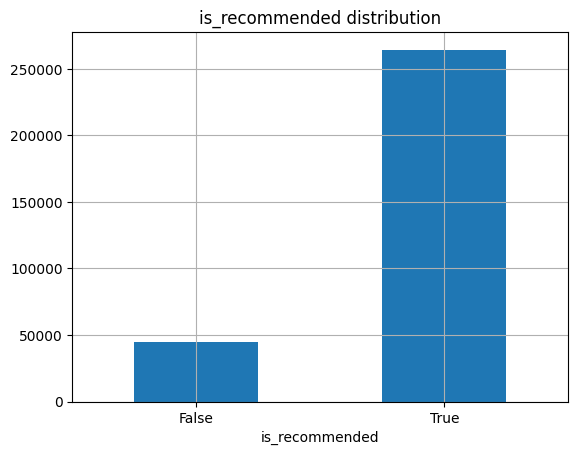

In [7]:
recommendations_df["is_recommended"].value_counts().sort_index().plot.bar(title="is_recommended distribution", rot=0).grid();

Распределение часов игры (по отзывам)


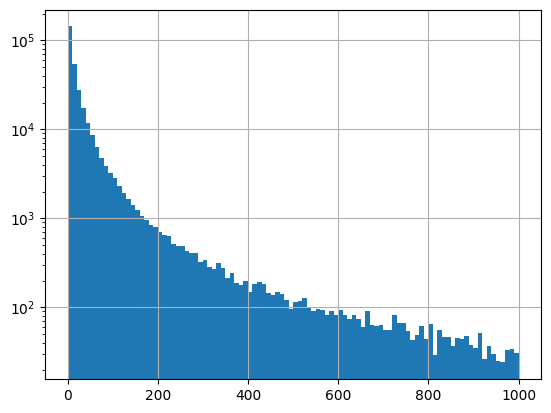

In [8]:
recommendations_df["hours"].hist(bins=100, log=True)
print('Распределение часов игры (по отзывам)')

Распределение пользователей (по отзывам)


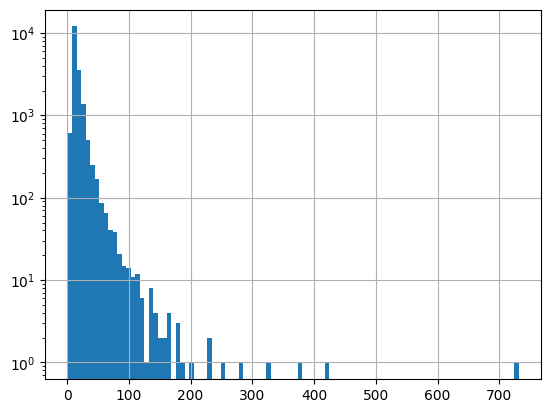

In [9]:
recommendations_df.groupby("user_id")["is_recommended"].count().hist(bins=100, log=True)
print('Распределение пользователей (по отзывам)')

Распределение игр (по отзывам)


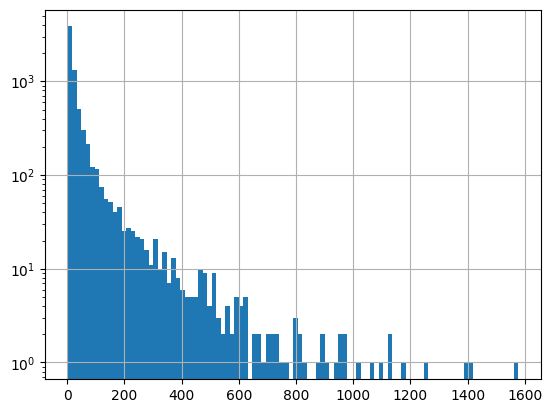

In [10]:
recommendations_df.groupby("app_id")["is_recommended"].count().hist(bins=100, log=True)
print('Распределение игр (по отзывам)')

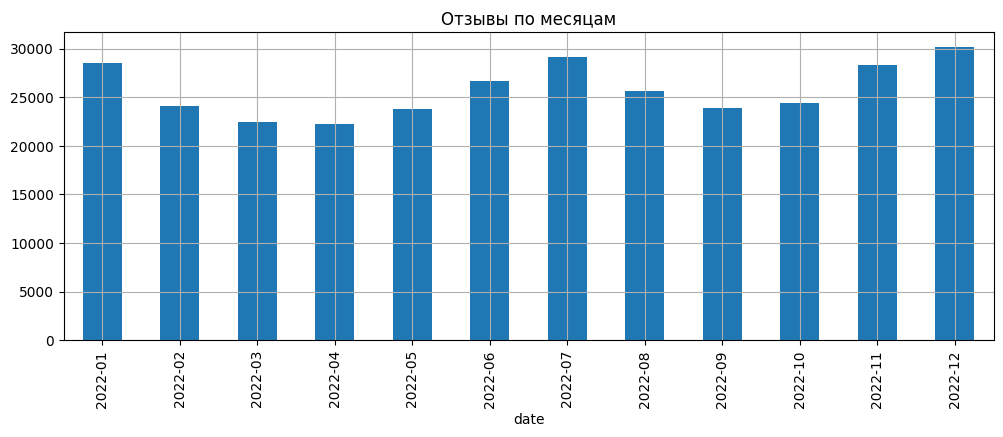

In [11]:
monthly = recommendations_df['date'].dt.to_period("M").value_counts().sort_index()
monthly.plot(kind="bar", figsize=(12, 4), title="Отзывы по месяцам", grid=True)
plt.show()

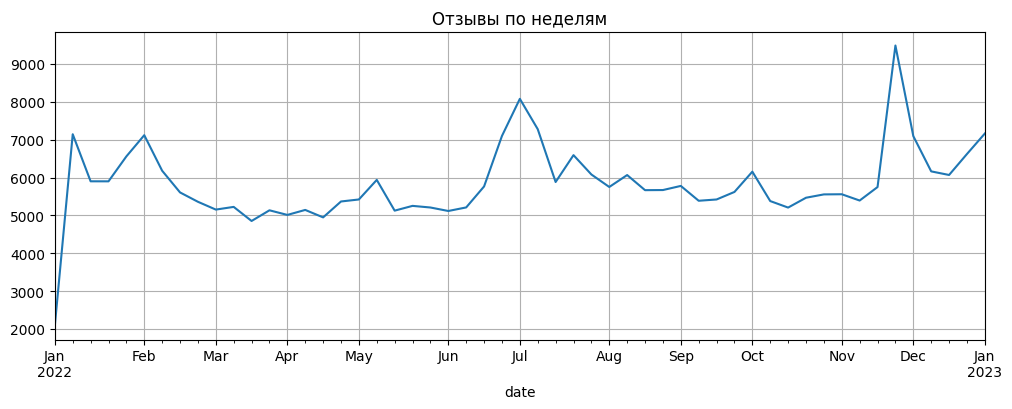

In [12]:
weekly = recommendations_df['date'].dt.to_period("W").value_counts().sort_index()
weekly.plot(figsize=(12, 4), title="Отзывы по неделям", grid=True)
plt.show()

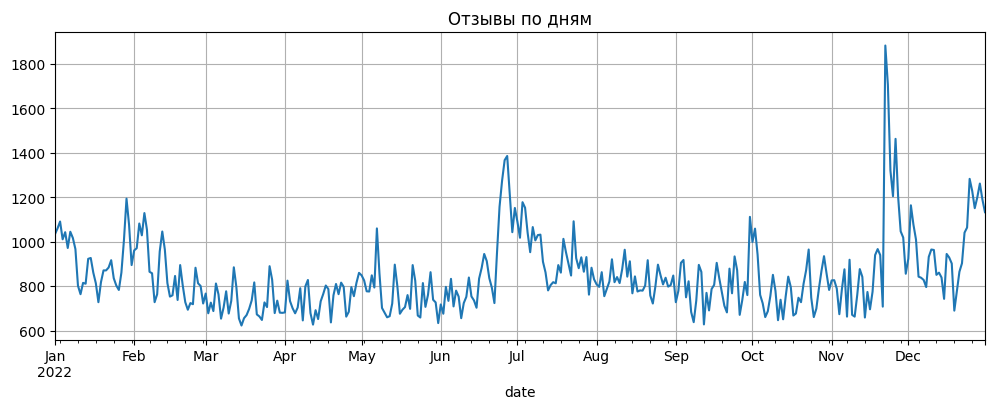

In [13]:
daily = recommendations_df['date'].dt.to_period("D").value_counts().sort_index()
daily.plot(figsize=(12, 4), title="Отзывы по дням", grid=True)
plt.show()

Распределение игр по рейтингу (% положительных отзывов)


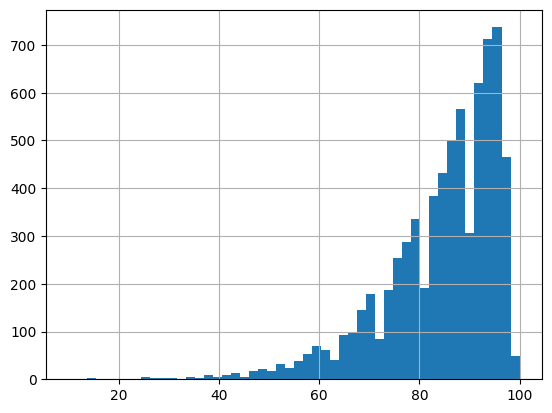

In [14]:
games_df["positive_ratio"].hist(bins=50, log=False)
print('Распределение игр по рейтингу (% положительных отзывов)')

Распределение игр по цене в $


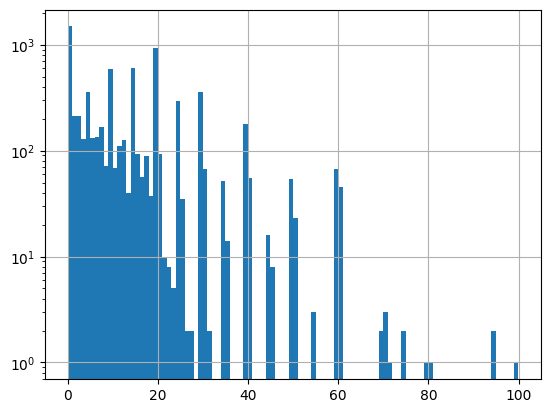

In [15]:
games_df["price_final"].hist(bins=100, log=True)
print('Распределение игр по цене в $')

Распределение отзывов по играм


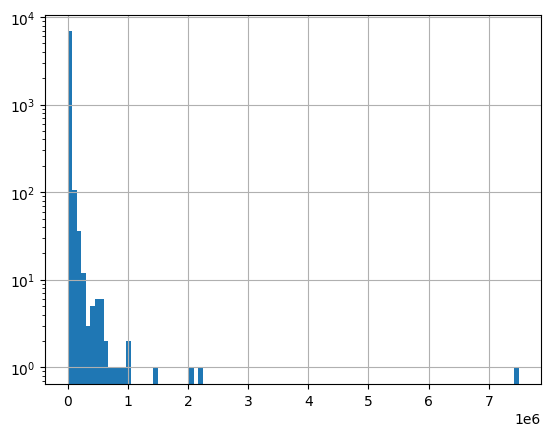

In [16]:
games_df["user_reviews"].hist(bins=100, log=True)
print('Распределение отзывов по играм')

Распределение игр по годам релиза


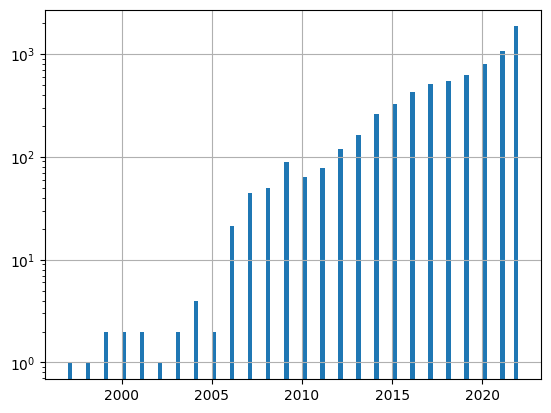

In [17]:
pd.to_datetime(games_df["date_release"]).dt.year.clip(1997, 2022).hist(bins=100, log=True)
print('Распределение игр по годам релиза')

Распределение купленных игр по пользователям


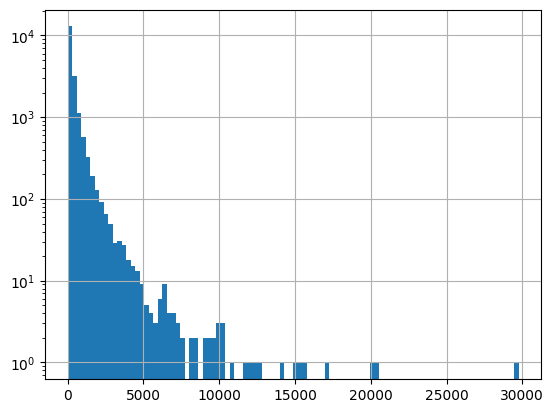

In [18]:
users_df["products"].hist(bins=100, log=True)
print('Распределение купленных игр по пользователям')

Распределение отзывов по пользователям


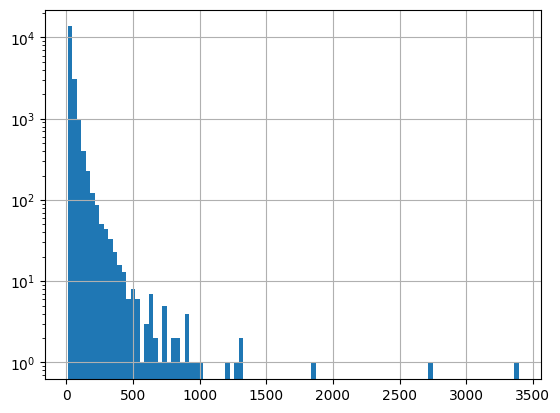

In [19]:
users_df["reviews"].hist(bins=100, log=True)
print('Распределение отзывов по пользователям')

###**пропусков, дубликатов нет**

## train/val/test split

* временное разбиение 70/15/15
* из val и test уберём user и app, которые есть в train
* Кандидаты для пользователя - все игры из train, кроме тех, с которыми он уже взаимодействовал в train
* Правила исключения уже известных объектов - убираем игры, с которыми он уже взаимодействовал в train
* Метрики Precision@10, NDCG@10. Выбираем NDCG@10, т.к. это универсальная метрика. Precision@10, т.к. нам важно, чтобы среди рекоммендаций были релевантные игры и не важно, чтобы все релевантные игры были рекоммендованы. NDCG@10 покажет, как хорошо мы проранжировали игры
* Основная метрика NDCG@10

In [20]:
recommendations_df = recommendations_df.sort_values("date").reset_index(drop=True)

q70 = recommendations_df["date"].quantile(0.70)
q85 = recommendations_df["date"].quantile(0.85)
print("граница train/val:", q70)
print("граница val/test :", q85)

train = recommendations_df[recommendations_df["date"] <  q70].copy()
val   = recommendations_df[(recommendations_df["date"] >= q70) & (recommendations_df["date"] < q85)].copy()
test  = recommendations_df[recommendations_df["date"] >= q85].copy()

print("train:", train.shape, "val:", val.shape, "test:", test.shape)
print(f"доли: {len(train)/len(recommendations_df):.4}, {len(val)/len(recommendations_df):.4}, {len(test)/len(recommendations_df):.4}")

граница train/val: 2022-09-18 00:00:00
граница val/test : 2022-11-16 00:00:00
train: (215734, 8) val: (46620, 8) test: (46928, 8)
доли: 0.6975, 0.1507, 0.1517


In [21]:
for name, d in [("train", train), ("val  ", val), ("test ", test)]:
    print(f"{name}: users={d['user_id'].nunique()}, "
          f"games={d['app_id'].nunique()}, n={len(d)}")

# Новые пользователи/игры в val и test
train_users = set(train["user_id"])
train_games = set(train["app_id"])

for name, d in [("val  ", val), ("test ", test)]:
    new_u = (~d["user_id"].isin(train_users)).sum()
    new_g = (~d["app_id"].isin(train_games)).sum()
    print(f"{name}: строк с новыми пользователями={new_u}, с новыми играми={new_g}")

train: users=18269, games=6548, n=215734
val  : users=13078, games=5331, n=46620
test : users=13412, games=5324, n=46928
val  : строк с новыми пользователями=3253, с новыми играми=6608
test : строк с новыми пользователями=4771, с новыми играми=8100


In [22]:
val = val[val['app_id'].isin(train_games) & val['user_id'].isin(train_users)]
test = test[test['app_id'].isin(train_games) & test['user_id'].isin(train_users)]

In [23]:
print("val :", val.shape,  "users:", val["user_id"].nunique(),  "games:", val["app_id"].nunique())
print("test:", test.shape, "users:", test["user_id"].nunique(), "games:", test["app_id"].nunique())

val : (36864, 8) users: 11560 games: 4938
test: (34263, 8) users: 11392 games: 4771


#1. Коллаборативная фильтрация на основе соседей: user-based или item-based

$s(u,v)$ - это cosine similarity с "+regularization" в знаменателе

N(u) — top-k_neighbors пользователей по s(u,v)

$r_{vi}$ = 1, если взамодействие есть и is_recomended=True, 0 иначе

score item-а i для user-а u $r_{ui} = \frac{\sum_{v \in N(u)}s(u,v)r_{vi}}{\sum_{v \in N(u)}|s(u,v)|}$

Берётся top-10 предсказаний (item-ов) по score для user-а



In [ ]:
estim = UserBasedCollaborativeFiltering(train)
estim.train()
app_to_title = dict(zip(games_df["app_id"], games_df["title"]))
metrics = estim.test(val, debug=True, app_to_title=app_to_title)
print(metrics)

Тренировка: ["Assassin's Creed® Odyssey", 'Mirror 2: Project X', 'Knell of St. Godhrkar', '怕不怕趴喵霸霸 Ghost Party Nyanbaba', '冷血症骰子', '9-nine-:Episode 1', 'Nioh: Complete Edition', 'Subnautica', 'Lacuna – A Sci-Fi Noir Adventure', 'Between the Stars', 'Ghostrunner', 'To the Moon', 'Chinese Driving Test Simulator', 'Sword and Fairy 7', 'ELDEN RING', 'Alice: Madness Returns', '9-nine-:Episode 2', 'Cut', "Evan's Remains", 'Milk outside a bag of milk outside a bag of milk', 'Finding Paradise', 'Miss Neko 2', 'Valiant Hearts: The Great War™ / Soldats Inconnus : Mémoires de la Grande Guerre™', 'STAR WARS Jedi: Fallen Order™', 'pemsa', 'Raft', 'Hollow Knight', 'Titanfall® 2', 'Outer Wilds', '9-nine-:Episode 3', 'Genesis Noir', 'Shortest Trip to Earth', '9-nine-:Episode 4', 'The Incredible Adventures of Van Helsing: Final Cut', 'Epistory - Typing Chronicles', "Dragon's Dogma: Dark Arisen", 'NEEDY STREAMER OVERLOAD', 'Hexcells', 'Hexcells Plus', 'Hexcells Infinite', 'The Surge', 'Noita', 'Mass Eff

/tmp/ipykernel_6912/1296457116.py:43: RuntimeWarning: invalid value encountered in divide
  sim = np.where(denom > 0, dot / denom, 0.0)


In [ ]:
regularizations = [0, 1, 5, 10, 20]
k_neighbors_list = [None, 10, 20, 50, 100, 500, 1000]

estim = UserBasedCollaborativeFiltering(train)
estim.train()

runs = []
for regularization, kn in tqdm(list(itertools.product(regularizations, k_neighbors_list))):
    metrics = estim.test(val, regularization=regularization, k_neighbors=kn)
    runs.append({**metrics, 'regularization': regularization, 'k_neighbors': kn})

  0%|          | 0/35 [00:00<?, ?it/s]/tmp/ipykernel_6912/1296457116.py:43: RuntimeWarning: invalid value encountered in divide
  sim = np.where(denom > 0, dot / denom, 0.0)
/tmp/ipykernel_6912/1296457116.py:55: RuntimeWarning: invalid value encountered in divide
  scores = nom / den
100%|██████████| 35/35 [27:45<00:00, 47.60s/it]

{'precision': 0.018084807638303342, 'ndcg': np.float64(0.045032334749353566), 'regularization': 0, 'k_neighbors': None}
{'precision': 0.009089207151549107, 'ndcg': np.float64(0.02461800626759337), 'regularization': 0, 'k_neighbors': 10}
{'precision': 0.011934849761302796, 'ndcg': np.float64(0.03218365965319996), 'regularization': 0, 'k_neighbors': 20}
{'precision': 0.016175231676494938, 'ndcg': np.float64(0.04268312880991699), 'regularization': 0, 'k_neighbors': 50}
{'precision': 0.018571562295234895, 'ndcg': np.float64(0.048622189618850294), 'regularization': 0, 'k_neighbors': 100}
{'precision': 0.01921744828231714, 'ndcg': np.float64(0.04928941736545757), 'regularization': 0, 'k_neighbors': 500}
{'precision': 0.018740054291865035, 'ndcg': np.float64(0.04732388385724416), 'regularization': 0, 'k_neighbors': 1000}
{'precision': 0.01808480763830334, 'ndcg': np.float64(0.044922063455308865), 'regularization': 1, 'k_neighbors': None}
{'precision': 0.0096882898062341, 'ndcg': np.float64(0.

In [ ]:
runs_sorted = sorted(runs, key=lambda r: r['ndcg'], reverse=True)
print('Лучшие запуски:')
print('precision  ndcg     regularization  k_neighbors')
for run in runs_sorted[:10]:
    print(f'{run["precision"]:.5f}    {run["ndcg"]:.5f}  {run["regularization"]:<2}              {run["k_neighbors"]}')

Лучшие запуски:
precision  ndcg     regularization  k_neighbors
0.01922    0.04929  0               500
0.01868    0.04927  5               100
0.01903    0.04915  10              100
0.01930    0.04873  20              500
0.01916    0.04867  1               500
0.01857    0.04862  0               100
0.01842    0.04862  1               100
0.01924    0.04858  10              500
0.01892    0.04855  20              100
0.01921    0.04851  5               500


In [ ]:
best = runs_sorted[0]
regularization = best['regularization']
kn = best['k_neighbors']

metrics_test = estim.test(test, regularization=regularization, k_neighbors=kn)
print(metrics_test)

/tmp/ipykernel_6912/1296457116.py:43: RuntimeWarning: invalid value encountered in divide
  sim = np.where(denom > 0, dot / denom, 0.0)
/tmp/ipykernel_6912/1296457116.py:55: RuntimeWarning: invalid value encountered in divide
  scores = nom / den


{'precision': 0.020590454631201065, 'ndcg': np.float64(0.05262251746185015)}


#2. ALS

Мы используем implicit ALS, т.к. если пользователь не играл в игру, то это мягкий негативный сигнал. iALS используется для explicit сигнала (положительный отзыв)

$p_{ij}$ = 1, если взамодействие есть и is_recomended=True, 0 иначе

$c_{ij} = 1 + \alpha |p_{ij}|$

$\min_{X,Y} \sum_{ij} c_{ij}(p_{ij} - x_i^Ty_j)^2 + λ\sum_i\|x_i\|^2C_i + λ\sum_j\|y_j\|^2C_j$
Берётся top-10 предсказаний (item-ов) по score для user-а



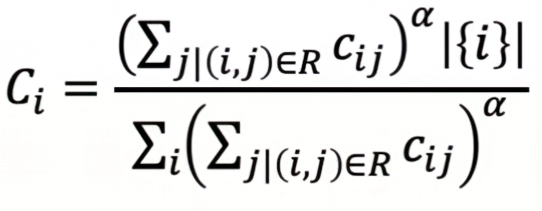

Ниже формула для обновления матрицы X. Метод обновляет сначала X, потом Y, и по кругу

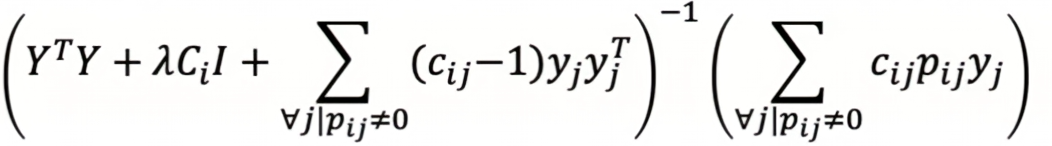

Предсказание: top-10 близких эмбеддингов item-ов к эмбеддингу user-a (эмбеддинги - матрицы X и Y). По скалярному произведению

In [ ]:
estim = ALS(train)
estim.train(d=16, epoch_num=15, alpha=10.0, lambd=0.1)
app_to_title = dict(zip(games_df["app_id"], games_df["title"]))

In [ ]:
metrics = estim.test(val, debug=True, app_to_title=app_to_title)
print(metrics)

Тренировка: ["Assassin's Creed® Odyssey", 'Mirror 2: Project X', 'Knell of St. Godhrkar', '怕不怕趴喵霸霸 Ghost Party Nyanbaba', '冷血症骰子', '9-nine-:Episode 1', 'Nioh: Complete Edition', 'Subnautica', 'Lacuna – A Sci-Fi Noir Adventure', 'Between the Stars', 'Ghostrunner', 'To the Moon', 'Chinese Driving Test Simulator', 'Sword and Fairy 7', 'ELDEN RING', 'Alice: Madness Returns', '9-nine-:Episode 2', 'Cut', "Evan's Remains", 'Milk outside a bag of milk outside a bag of milk', 'Finding Paradise', 'Miss Neko 2', 'Valiant Hearts: The Great War™ / Soldats Inconnus : Mémoires de la Grande Guerre™', 'STAR WARS Jedi: Fallen Order™', 'pemsa', 'Raft', 'Hollow Knight', 'Titanfall® 2', 'Outer Wilds', '9-nine-:Episode 3', 'Genesis Noir', 'Shortest Trip to Earth', '9-nine-:Episode 4', 'The Incredible Adventures of Van Helsing: Final Cut', 'Epistory - Typing Chronicles', "Dragon's Dogma: Dark Arisen", 'NEEDY STREAMER OVERLOAD', 'Hexcells', 'Hexcells Plus', 'Hexcells Infinite', 'The Surge', 'Noita', 'Mass Eff

In [ ]:
d_list      = [16, 32]
epoch_list  = [10]
alpha_list  = [10.0, 40.0]
lambda_list = [0.01, 0.1]
gamma_list = [0.2, 0.6]

runs_als = []
for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [True, False]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 16/16 [21:59<00:00, 82.45s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.019292,0.047632,False,32,10,10.0,0.10,0.6
1,0.019283,0.047595,False,32,10,10.0,0.01,0.2
2,0.019274,0.047571,False,32,10,10.0,0.01,0.6
3,0.019283,0.047561,False,32,10,10.0,0.10,0.2
4,0.018806,0.046439,False,16,10,10.0,0.01,0.6
5,0.018806,0.046438,False,16,10,10.0,0.01,0.2
6,0.018806,0.046437,False,16,10,10.0,0.10,0.2
7,0.018815,0.046422,False,16,10,10.0,0.10,0.6
8,0.018628,0.046159,False,16,10,40.0,0.01,0.6
9,0.018628,0.046159,False,16,10,40.0,0.01,0.2


In [ ]:
d_list      = [32, 64]
epoch_list  = [10]
alpha_list  = [5.0, 10.0, 40.0]
lambda_list = [0.01, 0.1, 0.5]
gamma_list = [0.2, 0.6]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 36/36 [55:41<00:00, 92.81s/it] 


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(20)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.019264,0.047861,False,32,10,10.0,0.50,0.6
1,0.019292,0.047632,False,32,10,10.0,0.10,0.6
2,0.019292,0.047632,False,32,10,10.0,0.10,0.6
3,0.018328,0.047626,False,64,10,10.0,0.50,0.6
4,0.019274,0.047608,False,32,10,10.0,0.50,0.2
5,0.019283,0.047595,False,32,10,10.0,0.01,0.2
6,0.019283,0.047595,False,32,10,10.0,0.01,0.2
7,0.019274,0.047571,False,32,10,10.0,0.01,0.6
8,0.019274,0.047571,False,32,10,10.0,0.01,0.6
9,0.019283,0.047561,False,32,10,10.0,0.10,0.2


In [ ]:
d_list      = [32,]
epoch_list  = [10,]
alpha_list  = [10,]
lambda_list = [0.1, 0.5, 1, 2, 5]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 5/5 [05:34<00:00, 66.81s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(20)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.019704,0.048742,False,32,10,10.0,5.00,0.6
1,0.019330,0.047917,False,32,10,10.0,2.00,0.6
2,0.019264,0.047861,False,32,10,10.0,0.50,0.6
3,0.019264,0.047861,False,32,10,10.0,0.50,0.6
4,0.019311,0.047828,False,32,10,10.0,1.00,0.6
5,0.019292,0.047632,False,32,10,10.0,0.10,0.6
6,0.019292,0.047632,False,32,10,10.0,0.10,0.6
7,0.019292,0.047632,False,32,10,10.0,0.10,0.6
8,0.018328,0.047626,False,64,10,10.0,0.50,0.6
9,0.019274,0.047608,False,32,10,10.0,0.50,0.2


In [ ]:
d_list      = [32,]
epoch_list  = [10,]
alpha_list  = [10,]
lambda_list = [20, 30, 50, 60, 70, 100]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 6/6 [06:33<00:00, 65.51s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.021445,0.054211,False,32,10,10.0,50.0,0.6
1,0.021445,0.054211,False,32,10,10.0,50.0,0.6
2,0.021230,0.053966,False,32,10,10.0,60.0,0.6
3,0.020622,0.052542,False,32,10,10.0,70.0,0.6
4,0.020856,0.052146,False,32,10,10.0,30.0,0.6
5,0.020303,0.050675,False,32,10,10.0,20.0,0.6
6,0.020303,0.050675,False,32,10,10.0,20.0,0.6
7,0.019985,0.049576,False,32,10,10.0,10.0,0.6
8,0.019704,0.048742,False,32,10,10.0,5.0,0.6
9,0.019704,0.048742,False,32,10,10.0,5.0,0.6


In [ ]:
d_list      = [32,]
epoch_list  = [10,]
alpha_list  = [5, 10, 20, 50, 100]
lambda_list = [50]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 5/5 [05:37<00:00, 67.44s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.021445,0.054211,False,32,10,10.0,50.0,0.6
1,0.021445,0.054211,False,32,10,10.0,50.0,0.6
2,0.021445,0.054211,False,32,10,10.0,50.0,0.6
3,0.021230,0.053966,False,32,10,10.0,60.0,0.6
4,0.020949,0.052619,False,32,10,20.0,50.0,0.6
5,0.020622,0.052542,False,32,10,10.0,70.0,0.6
6,0.020856,0.052146,False,32,10,10.0,30.0,0.6
7,0.020303,0.050675,False,32,10,10.0,20.0,0.6
8,0.020303,0.050675,False,32,10,10.0,20.0,0.6
9,0.019985,0.049576,False,32,10,10.0,10.0,0.6


In [ ]:
d_list      = [32,]
epoch_list  = [10, 20, 30, 40]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 4/4 [09:20<00:00, 140.15s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.021679,0.054749,False,32,20,10.0,50.0,0.6
1,0.021436,0.054650,False,32,30,10.0,50.0,0.6
2,0.021389,0.054502,False,32,40,10.0,50.0,0.6
3,0.021445,0.054211,False,32,10,10.0,50.0,0.6
4,0.021445,0.054211,False,32,10,10.0,50.0,0.6
5,0.021445,0.054211,False,32,10,10.0,50.0,0.6
6,0.021445,0.054211,False,32,10,10.0,50.0,0.6
7,0.021230,0.053966,False,32,10,10.0,60.0,0.6
8,0.020949,0.052619,False,32,10,20.0,50.0,0.6
9,0.020622,0.052542,False,32,10,10.0,70.0,0.6


In [ ]:
d_list      = [32,]
epoch_list  = [20,]
alpha_list  = [5, 10, 20, 50]
lambda_list = [50]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 4/4 [08:06<00:00, 121.57s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.021679,0.054749,False,32,20,10.0,50.0,0.6
1,0.021679,0.054749,False,32,20,10.0,50.0,0.6
2,0.021436,0.054650,False,32,30,10.0,50.0,0.6
3,0.021389,0.054502,False,32,40,10.0,50.0,0.6
4,0.021445,0.054211,False,32,10,10.0,50.0,0.6
5,0.021445,0.054211,False,32,10,10.0,50.0,0.6
6,0.021445,0.054211,False,32,10,10.0,50.0,0.6
7,0.021445,0.054211,False,32,10,10.0,50.0,0.6
8,0.021258,0.054056,False,32,20,20.0,50.0,0.6
9,0.021230,0.053966,False,32,10,10.0,60.0,0.6


In [ ]:
d_list      = [16, 32, 64]
epoch_list  = [15, 20, 25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]

for d, epoch_num, alpha, lambd, gamma in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list
))):
    estim = ALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma)
    for cos_sim in [False,]:
        metrics = estim.test(val, cos_sim=cos_sim)
        runs_als.append({
            **metrics, 'cos_sim': cos_sim,
            'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma
        })

100%|██████████| 9/9 [19:12<00:00, 128.04s/it]


In [ ]:
pd.DataFrame(runs_als).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,cos_sim,d,epoch_num,alpha,lambd,gamma
0,0.021651,0.055335,False,64,25,10.0,50.0,0.6
1,0.021661,0.055153,False,64,20,10.0,50.0,0.6
2,0.021473,0.055038,False,64,15,10.0,50.0,0.6
3,0.021576,0.054927,False,32,25,10.0,50.0,0.6
4,0.021679,0.054749,False,32,20,10.0,50.0,0.6
5,0.021679,0.054749,False,32,20,10.0,50.0,0.6
6,0.021679,0.054749,False,32,20,10.0,50.0,0.6
7,0.021436,0.054650,False,32,30,10.0,50.0,0.6
8,0.021623,0.054540,False,32,15,10.0,50.0,0.6
9,0.021389,0.054502,False,32,40,10.0,50.0,0.6


In [ ]:
runs_als.sort(key=lambda x: -x['ndcg'])
best = runs_als[0]
print("Лучшая конфигурация:", best)

estim = ALS(train)
estim.train(d=best['d'], epoch_num=best['epoch_num'], alpha=best['alpha'], lambd=best['lambd'], gamma=best['gamma'])
metrics_test = estim.test(test, cos_sim=best['cos_sim'])
print(metrics_test)

Лучшая конфигурация: {'precision': 0.0216512215669749, 'ndcg': np.float64(0.05533543535713704), 'cos_sim': False, 'd': 64, 'epoch_num': 25, 'alpha': 10, 'lambd': 50, 'gamma': 0.6}
{'precision': 0.020467836257309358, 'ndcg': np.float64(0.052613252673808064)}


# 3. EASE

X=A - это матрица рекоммендаций (1 где is_recomended=True, 0 иначе)

B=W - это обучаемые веса модели

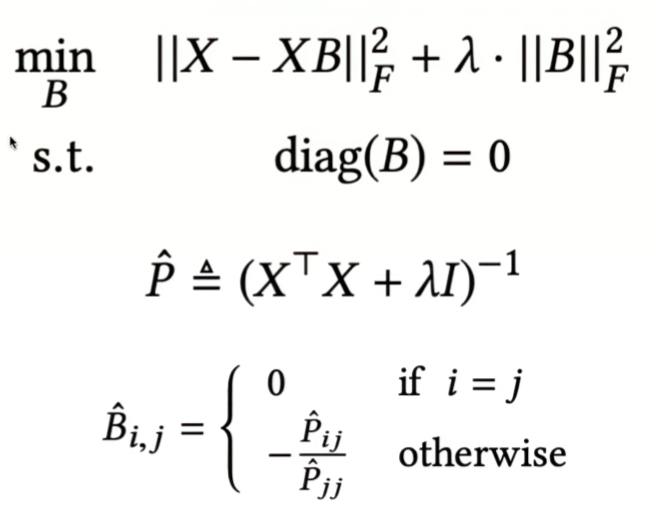

Ниже предсказание модели. Item-ы сортируются по весам и рекоммендуются top-10

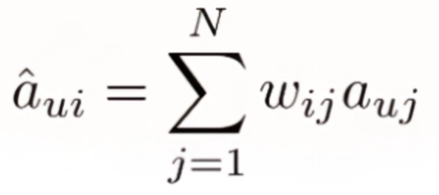

In [ ]:
estim = EASE(train)
estim.train(lambd=0.5)
metrics = estim.test(val, debug=True, app_to_title=app_to_title)
print(metrics)

Тренировка: ["Assassin's Creed® Odyssey", 'Mirror 2: Project X', 'Knell of St. Godhrkar', '怕不怕趴喵霸霸 Ghost Party Nyanbaba', '冷血症骰子', '9-nine-:Episode 1', 'Nioh: Complete Edition', 'Subnautica', 'Lacuna – A Sci-Fi Noir Adventure', 'Between the Stars', 'Ghostrunner', 'To the Moon', 'Chinese Driving Test Simulator', 'Sword and Fairy 7', 'ELDEN RING', 'Alice: Madness Returns', '9-nine-:Episode 2', 'Cut', "Evan's Remains", 'Milk outside a bag of milk outside a bag of milk', 'Finding Paradise', 'Miss Neko 2', 'Valiant Hearts: The Great War™ / Soldats Inconnus : Mémoires de la Grande Guerre™', 'STAR WARS Jedi: Fallen Order™', 'pemsa', 'Raft', 'Hollow Knight', 'Titanfall® 2', 'Outer Wilds', '9-nine-:Episode 3', 'Genesis Noir', 'Shortest Trip to Earth', '9-nine-:Episode 4', 'The Incredible Adventures of Van Helsing: Final Cut', 'Epistory - Typing Chronicles', "Dragon's Dogma: Dark Arisen", 'NEEDY STREAMER OVERLOAD', 'Hexcells', 'Hexcells Plus', 'Hexcells Infinite', 'The Surge', 'Noita', 'Mass Eff

In [ ]:
lambda_list = [0.01, 0.1, 0.5, 1, 2, 5, 10]

runs_ease = []
for lambd in tqdm(list(itertools.product(
    lambda_list,
))):
    estim = EASE(train)
    estim.train(lambd=lambd)
    metrics = estim.test(val)
    runs_ease.append({
        **metrics, 'lambd': lambd
    })

100%|██████████| 7/7 [05:59<00:00, 51.41s/it]


In [ ]:
pd.DataFrame(runs_ease).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,lambd
0,0.019143,0.050427,"(10,)"
1,0.018319,0.047884,"(5,)"
2,0.017102,0.045030,"(2,)"
3,0.016128,0.042753,"(1,)"
4,0.015520,0.041270,"(0.5,)"
5,0.015005,0.039908,"(0.1,)"
6,0.014631,0.038962,"(0.01,)"


In [ ]:
lambda_list = [20, 50, 100, 200]

for lambd in tqdm(list(itertools.product(
    lambda_list,
))):
    estim = EASE(train)
    estim.train(lambd=lambd)
    metrics = estim.test(val)
    runs_ease.append({
        **metrics, 'lambd': lambd
    })

100%|██████████| 4/4 [03:42<00:00, 55.71s/it]


In [ ]:
pd.DataFrame(runs_ease).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,lambd
0,0.021623,0.055597,"(100,)"
1,0.021698,0.055251,"(200,)"
2,0.021193,0.055037,"(50,)"
3,0.020004,0.052311,"(20,)"
4,0.019143,0.050427,"(10,)"
5,0.018319,0.047884,"(5,)"
6,0.017102,0.045030,"(2,)"
7,0.016128,0.042753,"(1,)"
8,0.015520,0.041270,"(0.5,)"
9,0.015005,0.039908,"(0.1,)"


In [ ]:
lambda_list = [80, 120, 150]

for lambd in tqdm(list(itertools.product(
    lambda_list,
))):
    estim = EASE(train)
    estim.train(lambd=lambd)
    metrics = estim.test(val)
    runs_ease.append({
        **metrics, 'lambd': lambd
    })

100%|██████████| 3/3 [02:20<00:00, 46.75s/it]


In [ ]:
pd.DataFrame(runs_ease).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,lambd
0,0.021754,0.055904,"(120,)"
1,0.021885,0.055879,"(150,)"
2,0.021623,0.055597,"(100,)"
3,0.021427,0.055421,"(80,)"
4,0.021698,0.055251,"(200,)"
5,0.021193,0.055037,"(50,)"
6,0.020004,0.052311,"(20,)"
7,0.019143,0.050427,"(10,)"
8,0.018319,0.047884,"(5,)"
9,0.017102,0.045030,"(2,)"


In [ ]:
lambda_list = [110, 130]

for lambd in tqdm(list(itertools.product(
    lambda_list,
))):
    estim = EASE(train)
    estim.train(lambd=lambd)
    metrics = estim.test(val)
    runs_ease.append({
        **metrics, 'lambd': lambd
    })

100%|██████████| 2/2 [02:17<00:00, 68.50s/it]


In [ ]:
pd.DataFrame(runs_ease).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,lambd
0,0.021754,0.055904,"(120,)"
1,0.021885,0.055879,"(150,)"
2,0.021717,0.055827,"(110,)"
3,0.021764,0.055827,"(130,)"
4,0.021623,0.055597,"(100,)"
5,0.021427,0.055421,"(80,)"
6,0.021698,0.055251,"(200,)"
7,0.021193,0.055037,"(50,)"
8,0.020004,0.052311,"(20,)"
9,0.019143,0.050427,"(10,)"


In [ ]:
runs_ease.sort(key=lambda x: -x['ndcg'])
best = runs_ease[0]
print("Лучшая конфигурация:", best)

estim = EASE(train)
estim.train(lambd=best['lambd'])
metrics_test = estim.test(test)
print(metrics_test)

Лучшая конфигурация: {'precision': 0.02175418889824889, 'ndcg': np.float64(0.05590427282778522), 'lambd': (120,)}
{'precision': 0.019326542161855722, 'ndcg': np.float64(0.050283343376790135)}


#4. Факторизационная машина (FM)

Переделываем матрицу коллабораций (1 где is_recomended=True, 0 иначе) в такую

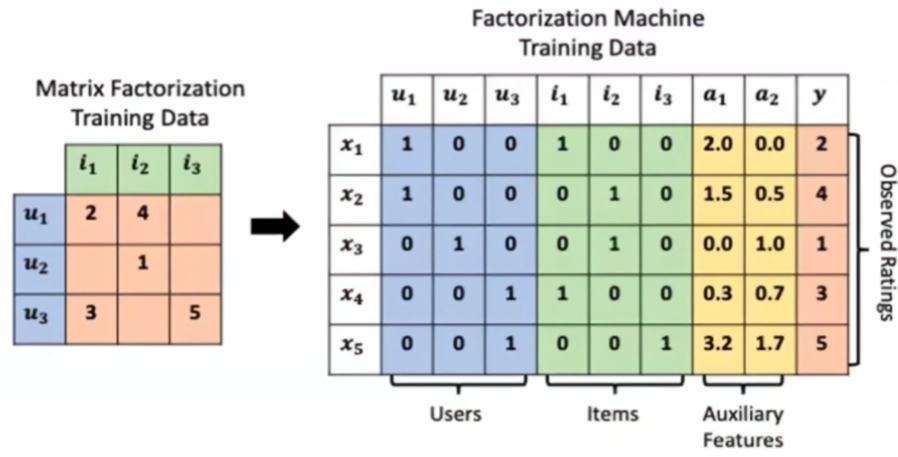

Модель:

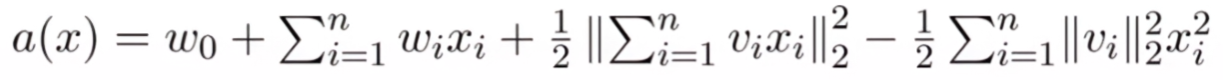

W - веса модели, X - новая матрица, y - рейтинг (везде = 1). Используется BPR-лосс (с семинара)

$-\ln \sigma \left( a(x^+) - a(x^-) \right) + \frac{\lambda}{2} \|W\|_2^2$

**Обоснуйте выбор признаков; используйте лишь информацию, доступную в момент рекомендации.**
- Характеристики взаимодействия hours, helpfull, funny мы использовать не можем, т.к. до покупки игры пользователь играл в неё 0 часов, а отзыв не мог быть написан

Будем использовать:

- User: products (log), reviews (log)

- App: год релиза (из date_release), user_reviews (log), price_final, positive_ratio, описание игры, тэги игры

Хотя reviews включает будущие отзывы пользователя, влияние это мало и оно не даёт информации о том, на какие игры он написал отзыв в будущем. Поэтому reviews можно взять. Аналогично с user_reviews для игр

Берём log у тех признаков, где разброс большой (см. EDA)

То, что пользователь оценивает/покупает много игр, говорит, что пользователь не новичок, и это может улучшить рекоммендации

User-у могут нравиться старые игры, поэтому возьмём год релиза для игры. user_reviews (log), price_final, positive_ratio, описание игры, тэги игры  тоже могут улучшить рекоммендации

* Для тегов мы проводим one-hot encoding для самых популярных тегов (число тегов - гиперпараметр)
* Для описания используем эмбеддинг описания и проецируем его с помощью PCA (размерность - гиперпараметр)
* Для остальных метаданных нормализируем на среднее и дисперсию


In [38]:
runs_fm = []

In [41]:
n_factors_list = [16]
epochs_list = [10,]
lr_list = [0.01]
reg_list = [1e-3]
top_tags_list = [20]
descr_emd_dim_list = [1, 2, 4, 8]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/4 [00:00<?, ?it/s]

Обработка топ-20 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24844 (включая 20 тегов и 16 эмбеддингов)


...

Обработка топ-20 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24851 (включая 20 тегов и 16 эмбеддингов)


100%|██████████| 4/4 [02:41<00:00, 40.30s/it]


In [42]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(20)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.010737,0.027230,16,10,0.01,0.001,20,2
1,0.011083,0.026810,16,10,0.01,0.001,20,8
2,0.011083,0.026810,16,10,0.01,0.001,20,8
3,0.011102,0.026745,16,10,0.01,0.001,20,16
4,0.011261,0.026730,16,10,0.01,0.001,20,64
5,0.010634,0.026261,16,10,0.01,0.001,20,4
6,0.010465,0.026210,16,10,0.01,0.001,20,1
7,0.010849,0.024979,16,10,0.01,0.001,20,32
8,0.010259,0.022716,16,10,0.01,0.001,20,128


In [43]:
n_factors_list = [16]
epochs_list = [10,]
lr_list = [0.01]
reg_list = [1e-3]
top_tags_list = [15, 20, 25]
descr_emd_dim_list = [2]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/3 [00:00<?, ?it/s]

Обработка топ-15 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24840 (включая 15 тегов и 16 эмбеддингов)


...

Обработка топ-25 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24850 (включая 25 тегов и 16 эмбеддингов)


100%|██████████| 3/3 [01:58<00:00, 39.48s/it]


In [45]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(5)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.010737,0.027230,16,10,0.01,0.001,20,2
1,0.010737,0.027230,16,10,0.01,0.001,20,2
2,0.010971,0.027117,16,10,0.01,0.001,25,2
3,0.010727,0.027007,16,10,0.01,0.001,15,2
4,0.011083,0.026810,16,10,0.01,0.001,20,8


In [46]:
n_factors_list = [8, 12, 16, 20, 24]
epochs_list = [10,]
lr_list = [0.01]
reg_list = [1e-3]
top_tags_list = [20]
descr_emd_dim_list = [2]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/5 [00:00<?, ?it/s]

Обработка топ-20 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 16 эмбеддингов)


...

Обработка топ-20 тегов...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 16 эмбеддингов)


100%|██████████| 5/5 [03:39<00:00, 43.91s/it]


In [47]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(5)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.010737,0.027230,16,10,0.01,0.001,20,2
1,0.010737,0.027230,16,10,0.01,0.001,20,2
2,0.010737,0.027230,16,10,0.01,0.001,20,2
3,0.010971,0.027117,16,10,0.01,0.001,25,2
4,0.010840,0.027020,24,10,0.01,0.001,20,2


In [53]:
n_factors_list = [16]
epochs_list = [8, 10, 12]
lr_list = [0.01]
reg_list = [1e-3]
top_tags_list = [20]
descr_emd_dim_list = [2]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)


 33%|███▎      | 1/3 [00:38<01:16, 38.20s/it]

...

 67%|██████▋   | 2/3 [01:27<00:44, 44.72s/it]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)


100%|██████████| 3/3 [02:12<00:00, 44.29s/it]


In [55]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.010737,0.027230,16,10,0.01,0.001,20,2
1,0.010737,0.027230,16,10,0.01,0.001,20,2
2,0.010737,0.027230,16,10,0.01,0.001,20,2
3,0.010737,0.027230,16,10,0.01,0.001,20,2
4,0.010737,0.027230,16,10,0.01,0.001,20,2
5,0.010971,0.027117,16,10,0.01,0.001,25,2
6,0.010840,0.027020,24,10,0.01,0.001,20,2
7,0.010727,0.027007,16,10,0.01,0.001,15,2
8,0.011083,0.026810,16,10,0.01,0.001,20,8
9,0.011083,0.026810,16,10,0.01,0.001,20,8


In [56]:
n_factors_list = [16]
epochs_list = [10]
lr_list = [0.01]
reg_list = [1e-2, 1e-3, 1e-4]
top_tags_list = [20]
descr_emd_dim_list = [2]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)


 33%|███▎      | 1/3 [00:47<01:35, 47.83s/it]

...

 67%|██████▋   | 2/3 [01:27<00:42, 42.93s/it]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)


100%|██████████| 3/3 [02:07<00:00, 42.54s/it]


In [57]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.011336,0.027719,16,10,0.01,0.0001,20,2
1,0.010737,0.027230,16,10,0.01,0.0010,20,2
2,0.010737,0.027230,16,10,0.01,0.0010,20,2
3,0.010737,0.027230,16,10,0.01,0.0010,20,2
4,0.010737,0.027230,16,10,0.01,0.0010,20,2
5,0.010737,0.027230,16,10,0.01,0.0010,20,2
6,0.010737,0.027230,16,10,0.01,0.0010,20,2
7,0.010971,0.027117,16,10,0.01,0.0010,25,2
8,0.010840,0.027020,24,10,0.01,0.0010,20,2
9,0.010727,0.027007,16,10,0.01,0.0010,15,2


In [58]:
n_factors_list = [16]
epochs_list = [10]
lr_list = [0.01]
reg_list = [1e-5]
top_tags_list = [20]
descr_emd_dim_list = [2]

for n_factors, epochs, lr, reg, top_tags, descr_emd_dim in tqdm(list(itertools.product(
    n_factors_list, epochs_list, lr_list, reg_list, top_tags_list, descr_emd_dim_list
))):
    fm_estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
    fm_estim.train(n_factors=n_factors, epochs=epochs, lr=lr, reg=reg, top_tags=top_tags, batch_size=4096, descr_emd_dim=descr_emd_dim)
    metrics = fm_estim.test(val)
    runs_fm.append({
        **metrics, 'n_factors': n_factors, 'epochs': epochs, 'lr': lr, 'reg': reg, 'top_tags': top_tags, 'descr_emd_dim': descr_emd_dim
    })

  0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)


100%|██████████| 1/1 [00:44<00:00, 44.50s/it]


In [60]:
pd.DataFrame(runs_fm).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,n_factors,epochs,lr,reg,top_tags,descr_emd_dim
0,0.011336,0.027719,16,10,0.01,0.0001,20,2
1,0.010737,0.027230,16,10,0.01,0.0010,20,2
2,0.010737,0.027230,16,10,0.01,0.0010,20,2
3,0.010737,0.027230,16,10,0.01,0.0010,20,2
4,0.010737,0.027230,16,10,0.01,0.0010,20,2
5,0.010737,0.027230,16,10,0.01,0.0010,20,2
6,0.010737,0.027230,16,10,0.01,0.0010,20,2
7,0.010971,0.027117,16,10,0.01,0.0010,25,2
8,0.010840,0.027020,24,10,0.01,0.0010,20,2
9,0.010727,0.027007,16,10,0.01,0.0010,15,2


In [62]:
runs_fm.sort(key=lambda x: -x['ndcg'])
best = runs_fm[0]
print("Лучшая конфигурация:", best)

estim = FM(train, games_df, users_df, metadata_path=f"{path}/games_metadata.json")
estim.train(n_factors=best['n_factors'], epochs=best['epochs'], lr=best['lr'],
            reg=best['reg'], top_tags=best['top_tags'], batch_size=4096, descr_emd_dim=best['descr_emd_dim'])
metrics_test = estim.test(test)
print(metrics_test)

Лучшая конфигурация: {'precision': 0.0113357671066178, 'ndcg': np.float64(0.027719388768579132), 'n_factors': 16, 'epochs': 10, 'lr': 0.01, 'reg': 0.0001, 'top_tags': 20, 'descr_emd_dim': 2}


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Итоговое число признаков: 24845 (включая 20 тегов и 2 эмбеддингов)
{'precision': 0.013186191284662986, 'ndcg': np.float64(0.03442772566622762)}


#5. iALS с самостоятельно разработанным целевым сигналом

Формулы аналогичные пункту 2, кроме $p_{ij}$

В iALS из пункта 2 негативные оценки игнорируется. Возьмём сигнал:

$p_{ij}$ =

$1 + hours * w_{pos\_hours}$, если is_recomended=True

$-w_{neg} + hours * w_{neg\_hours}$, если is_recomended=False

$0$, иначе

hours - это сколько часов играл пользователь в игру, на которую он написал отзыв

Эмпирически получены лучшие значения гиперпараметров
* neg_w = -0.6 (-neg_w = 0.6)
* hours_pos_w = 0.0002
* hours_neg_w = 0.002

In [39]:
runs_ials = []

In [27]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [0, 0.5, 1, 2]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 4/4 [20:02<00:00, 300.60s/it]


In [28]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.021361,0.055116,64,25,10,50,0.6,0.0
1,0.020678,0.053243,64,25,10,50,0.6,0.5
2,0.019367,0.050002,64,25,10,50,0.6,1.0
3,0.015829,0.040529,64,25,10,50,0.6,2.0


In [29]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [0, 0.1, 0.3]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 3/3 [14:38<00:00, 292.84s/it]


In [30]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.021361,0.055116,64,25,10,50,0.6,0.0
1,0.021361,0.055116,64,25,10,50,0.6,0.0
2,0.021183,0.054680,64,25,10,50,0.6,0.1
3,0.021164,0.054135,64,25,10,50,0.6,0.3
4,0.020678,0.053243,64,25,10,50,0.6,0.5
5,0.019367,0.050002,64,25,10,50,0.6,1.0
6,0.015829,0.040529,64,25,10,50,0.6,2.0


In [31]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [0.01]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 1/1 [05:17<00:00, 318.00s/it]


In [32]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.021361,0.055116,64,25,10,50,0.6,0.00
1,0.021361,0.055116,64,25,10,50,0.6,0.00
2,0.021333,0.055055,64,25,10,50,0.6,0.01
3,0.021183,0.054680,64,25,10,50,0.6,0.10
4,0.021164,0.054135,64,25,10,50,0.6,0.30
5,0.020678,0.053243,64,25,10,50,0.6,0.50
6,0.019367,0.050002,64,25,10,50,0.6,1.00
7,0.015829,0.040529,64,25,10,50,0.6,2.00


In [33]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.1]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 1/1 [05:00<00:00, 300.97s/it]


In [34]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.021801,0.055634,64,25,10,50,0.6,-0.10
1,0.021361,0.055116,64,25,10,50,0.6,0.00
2,0.021361,0.055116,64,25,10,50,0.6,0.00
3,0.021333,0.055055,64,25,10,50,0.6,0.01
4,0.021183,0.054680,64,25,10,50,0.6,0.10
5,0.021164,0.054135,64,25,10,50,0.6,0.30
6,0.020678,0.053243,64,25,10,50,0.6,0.50
7,0.019367,0.050002,64,25,10,50,0.6,1.00
8,0.015829,0.040529,64,25,10,50,0.6,2.00


In [35]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.25, -0.5, -1]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 3/3 [14:45<00:00, 295.28s/it]


In [36]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.022400,0.057058,64,25,10,50,0.6,-0.50
1,0.022054,0.056693,64,25,10,50,0.6,-1.00
2,0.021876,0.056093,64,25,10,50,0.6,-0.25
3,0.021801,0.055634,64,25,10,50,0.6,-0.10
4,0.021361,0.055116,64,25,10,50,0.6,0.00
5,0.021361,0.055116,64,25,10,50,0.6,0.00
6,0.021333,0.055055,64,25,10,50,0.6,0.01
7,0.021183,0.054680,64,25,10,50,0.6,0.10
8,0.021164,0.054135,64,25,10,50,0.6,0.30
9,0.020678,0.053243,64,25,10,50,0.6,0.50


In [39]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.6, -0.7, -0.8, -0.9]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 4/4 [19:46<00:00, 296.69s/it]


In [29]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.022456,0.057164,64,25,10,50,0.6,-0.60
1,0.022372,0.057161,64,25,10,50,0.6,-0.70
2,0.022306,0.057058,64,25,10,50,0.6,-0.80
3,0.022400,0.057058,64,25,10,50,0.6,-0.50
4,0.022232,0.056935,64,25,10,50,0.6,-0.90
5,0.022054,0.056693,64,25,10,50,0.6,-1.00
6,0.021876,0.056093,64,25,10,50,0.6,-0.25
7,0.021801,0.055634,64,25,10,50,0.6,-0.10
8,0.021361,0.055116,64,25,10,50,0.6,0.00
9,0.021361,0.055116,64,25,10,50,0.6,0.00


In [30]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.625 -0.65, -0.675]

for d, epoch_num, alpha, lambd, gamma, neg_weight in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight
    })

100%|██████████| 2/2 [09:16<00:00, 278.02s/it]


In [31]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight
0,0.022456,0.057164,64,25,10,50,0.6,-0.600
1,0.022372,0.057161,64,25,10,50,0.6,-0.700
2,0.022353,0.057077,64,25,10,50,0.6,-0.675
3,0.022306,0.057058,64,25,10,50,0.6,-0.800
4,0.022400,0.057058,64,25,10,50,0.6,-0.500
5,0.022232,0.056935,64,25,10,50,0.6,-0.900
6,0.022054,0.056693,64,25,10,50,0.6,-1.000
7,0.021876,0.056093,64,25,10,50,0.6,-0.250
8,0.021810,0.055897,64,25,10,50,0.6,-1.275
9,0.021801,0.055634,64,25,10,50,0.6,-0.100


In [41]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.6]
hours_pos_w_list = [0.0003, 0.0004]
hours_neg_w_list = [0]

for d, epoch_num, alpha, lambd, gamma, neg_weight, hours_pos_w, hours_neg_w in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list, hours_pos_w_list, hours_neg_w_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight, hours_pos_w=hours_pos_w, hours_neg_w=hours_neg_w)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight, 'hours_pos_w': hours_pos_w, 'hours_neg_w': hours_neg_w
    })

100%|██████████| 2/2 [08:45<00:00, 262.67s/it]


In [43]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(5)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight,hours_pos_w,hours_neg_w
0,0.022456,0.057414,64,25,10,50,0.6,-0.6,0.0002,0.0
1,0.022456,0.057374,64,25,10,50,0.6,-0.6,0.0004,0.0
2,0.022391,0.057286,64,25,10,50,0.6,-0.6,0.0003,0.0
3,0.022372,0.057200,64,25,10,50,0.6,-0.6,0.0005,0.0
4,0.022456,0.057189,64,25,10,50,0.6,-0.6,0.0001,0.0


In [57]:
d_list      = [64]
epoch_list  = [25]
alpha_list  = [10,]
lambda_list = [50]
gamma_list = [0.6,]
neg_weight_list = [-0.6]
hours_pos_w_list = [0.0002]
hours_neg_w_list = [0.0008, 0.002, 0.0015, 0.003]

for d, epoch_num, alpha, lambd, gamma, neg_weight, hours_pos_w, hours_neg_w in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list, hours_pos_w_list, hours_neg_w_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight, hours_pos_w=hours_pos_w, hours_neg_w=hours_neg_w)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight, 'hours_pos_w': hours_pos_w, 'hours_neg_w': hours_neg_w
    })

100%|██████████| 4/4 [17:42<00:00, 265.65s/it]


In [58]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(10)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight,hours_pos_w,hours_neg_w
0,0.022456,0.057564,64,25,10,50,0.6,-0.6,0.0002,0.0020
1,0.022503,0.057463,64,25,10,50,0.6,-0.6,0.0002,0.0010
2,0.022475,0.057454,64,25,10,50,0.6,-0.6,0.0002,0.0015
3,0.022466,0.057448,64,25,10,50,0.6,-0.6,0.0002,0.0008
4,0.022475,0.057414,64,25,10,50,0.6,-0.6,0.0002,0.0005
5,0.022456,0.057414,64,25,10,50,0.6,-0.6,0.0002,0.0000
6,0.022512,0.057395,64,25,10,50,0.6,-0.6,0.0002,-0.0001
7,0.022213,0.057395,64,25,10,50,0.6,-0.6,0.0002,0.0030
8,0.022456,0.057374,64,25,10,50,0.6,-0.6,0.0004,0.0000
9,0.022428,0.057313,64,25,10,50,0.6,-0.6,0.0002,0.0001


In [70]:
d_list      = [60, 64, 68]
epoch_list  = [20, 25, 30]
alpha_list  = [10]
lambda_list = [55]
gamma_list = [0.6,]
neg_weight_list = [-0.6]
hours_pos_w_list = [0.0002]
hours_neg_w_list = [0.002]

for d, epoch_num, alpha, lambd, gamma, neg_weight, hours_pos_w, hours_neg_w in tqdm(list(itertools.product(
    d_list, epoch_list, alpha_list, lambda_list, gamma_list, neg_weight_list, hours_pos_w_list, hours_neg_w_list
))):
    estim = IALS(train)
    estim.train(d=d, epoch_num=epoch_num, alpha=alpha, lambd=lambd, gamma=gamma, neg_weight=neg_weight, hours_pos_w=hours_pos_w, hours_neg_w=hours_neg_w)
    metrics = estim.test(val, cos_sim=False)
    runs_ials.append({
        **metrics, 'd': d, 'epoch_num': epoch_num, 'alpha': alpha, 'lambd': lambd, 'gamma': gamma, 'neg_weight': neg_weight, 'hours_pos_w': hours_pos_w, 'hours_neg_w': hours_neg_w
    })

100%|██████████| 9/9 [40:14<00:00, 268.24s/it]


In [75]:
pd.DataFrame(runs_ials).sort_values(by='ndcg', ascending=False).reset_index(drop=True).head(20)

,precision,ndcg,d,epoch_num,alpha,lambd,gamma,neg_weight,hours_pos_w,hours_neg_w
0,0.022512,0.057657,64,25,10,55,0.6,-0.6,0.0002,0.0020
1,0.022512,0.057657,64,25,10,55,0.6,-0.6,0.0002,0.0020
2,0.022475,0.057610,64,30,10,55,0.6,-0.6,0.0002,0.0020
3,0.022456,0.057564,64,25,10,50,0.6,-0.6,0.0002,0.0020
4,0.022456,0.057564,64,25,10,50,0.6,-0.6,0.0002,0.0020
5,0.022456,0.057564,64,25,10,50,0.6,-0.6,0.0002,0.0020
6,0.022466,0.057511,64,25,10,52,0.6,-0.6,0.0002,0.0020
7,0.022381,0.057478,60,30,10,55,0.6,-0.6,0.0002,0.0020
8,0.022503,0.057463,64,25,10,50,0.6,-0.6,0.0002,0.0010
9,0.022475,0.057454,64,25,10,50,0.6,-0.6,0.0002,0.0015


In [78]:
runs_ials.sort(key=lambda x: -x['ndcg'])
best = runs_ials[0]
print("Лучшая конфигурация:", best)

estim = IALS(train)
estim.train(
    d=best['d'],
    epoch_num=best['epoch_num'],
    alpha=best['alpha'],
    lambd=best['lambd'],
    gamma=best['gamma'],
    neg_weight=best['neg_weight'],
    hours_pos_w=best['hours_pos_w'],
    hours_neg_w=best['hours_neg_w']
)
metrics_test = estim.test(test, cos_sim=False)
print(metrics_test)

Лучшая конфигурация: {'precision': 0.022512402883084565, 'ndcg': np.float64(0.05765729545056518), 'd': 64, 'epoch_num': 25, 'alpha': 10, 'lambd': 55, 'gamma': 0.6, 'neg_weight': -0.6, 'hours_pos_w': 0.0002, 'hours_neg_w': 0.002}
{'precision': 0.020967741935483262, 'ndcg': np.float64(0.054047517925426156)}


# ВЫВОДЫ

In [49]:
results = [
    {"Метод": "5. iALS (свой сигнал)", "Precision@10": 0.02097, "NDCG@10": 0.05405,
     "Гиперпараметры": "d=64,  epochs=25,  alpha=10,  lambd=55,  gamma=0.6,  neg_weight=-0.6,  hours_pos_w=0.0002,  hours_neg_w=0.002,  cos_sim=False"},
    {"Метод": "1. User-based CF", "Precision@10": 0.02059, "NDCG@10": 0.05262,
     "Гиперпараметры": "regularization=0,  k_neighbors=500"},
    {"Метод": "2. iALS (базовый)", "Precision@10": 0.02047, "NDCG@10": 0.05261,
     "Гиперпараметры": "d=64,  epochs=25,  alpha=10,  lambd=50,  gamma=0.6,  cos_sim=False"},
    {"Метод": "3. EASE", "Precision@10": 0.01933, "NDCG@10": 0.05028,
     "Гиперпараметры": "lambd=120"},
    {"Метод": "4. FM", "Precision@10": 0.01319, "NDCG@10": 0.03443,
     "Гиперпараметры": "n_factors=16,  epochs=10,  lr=0.01,  reg=1e-4,  top_tags=20,  descr_emd_dim=2"},
]

df_results = pd.DataFrame(results)
df_results = df_results.sort_values("NDCG@10", ascending=False).reset_index(drop=True)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 250)

display(df_results)

,Метод,Precision@10,NDCG@10,Гиперпараметры
0,iALS (свой сигнал),0.02097,0.05405,"d=64, epochs=25, alpha=10, lambd=55, gamma=0.6, neg_weight=-0.6, hours_pos_w=0.0002, hours_neg_w=0.002, cos_sim=False"
1,User-based CF,0.02059,0.05262,"regularization=0, k_neighbors=50"
2,iALS (базовый),0.02047,0.05261,"d=64, epochs=25, alpha=10, lambd=50, gamma=0.6, cos_sim=False"
3,EASE,0.01933,0.05028,lambd=120
4,FM,0.01319,0.03443,"n_factors=16, epochs=10, lr=0.01, reg=1e-4, top_tags=20, descr_emd_dim=2"


**Какие методы и настройки оказались лучше, как повлияли метаданные или кастомный сигнал, какие ограничения есть у эксперимента**

* iALS (свой сигнал) оказался лучше всего и по NDCG, и по Precision. Кастомный сигнал позволил увеличить NDCG на 0.00144 (на test) по сравнению с iALS (базовым) => он был полезным. Больше всего увеличился NDCG благодаря учёту отзывов с is_recomended=False (на validation). Меня удивило, что прирост NDCG был, когда играм с is_recomended=False давали положительный вес. Это означает, что пользователь ставит is_recomended=False не из-за того, что жанр не нравится, а из-за того, что не нравится конкретная игра. Причём оптимальный вес дизлайков = 0.6.
* User-based CF оказался вторым => в нашей задаче такой простой алгоритм вполне рабочий
* FM оказался хуже всего с большим отрывом. Добавление метаданных уменьшило предсказательную способность модели

**Ограничения эксперимента**

* В 4-ом эксп. (FM) используются поля user_reviews и reviews. Это может являться утечкой данных. На момент рекоммендации мы не знаем reviews (общее количество отзывов пользователя), хотя за год оно не должно было сильно измениться, т.к. reviews - отзывы за всё время. Поэтому я этим пренебрёг
* train/val/test разбиты по времени (по квантилям). Но в Steam есть явная сезонность. test попал на период с 16 ноября. Тогда купленных игр становится больше (из-за распродажи). Распределения купленных игр могут отличаться